# Neural topology optimization
## Introduction
This notebook demonstrates how `metatopia` can be used to set up neural topology optimization for a single task. We'll walk through the key components of the optimization process, from setting up the problem to visualizing the results. First, let's import all necessary libraries:

In [10]:
import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import metatopia as mtp
import optax
from equinox.internal import scan
from metatopia.utils import plot_design


# Enable 64-bit precision
jax.config.update("jax_enable_x64", True)

## Problem setup
Let's start by setting up the solver used in the iterative procedure, and the boundary conditions for the Messerschmitt–Bölkow–Blohm (MBB) beam problem - a classic benchmark in topology optimization. 

In [11]:
# Define domain shape for MBB beam
Nx = 128  # Number of elements in the x-direction
Ny = 64  # Number of elements in the y-direction

# Define domain size
Lx = 2.0  # Domain size in the x-direction
Ly = 1.0  # Domain size in the y-direction

domain_shape = (Ny, Nx)

# Generate grid coordinates
coords = mtp.utils.get_grid_coords(domain_shape)

# Setup the solver
solver = mtp.solver.setup_solver_cvxopt(
    Nx=Nx,
    Ny=Ny,
    Lx=Lx,
    Ly=Ly,
    young=1.0,
    young_min=1e-9,
    poisson=0.3,
    penalty=3.0,
)

# Set up the MBB problem
problem = mtp.dataset.to.mbb_beam(width=Nx, height=Ny, target_vf=0.5)

# Calculate reference compliance for uniform design
reference_compliance = solver(jnp.ones(domain_shape) * problem["target_vf"], problem)
problem = eqx.tree_at(
    lambda x: x["reference_compliance"], problem, reference_compliance
)

## Create a neural reparameterization model
Now, let's create a neural network which will map the spatial coordinates of element centroids $\mathbf{x}\in \Omega$ to density values $\rho(\mathbf{x})$. We start by creating a grid of coordinates. 

In [12]:
coords = mtp.utils.get_grid_coords(domain_shape)

Next, we create a SIREN neural network to perform the mapping from 2D coordinates (`in_features=2`) to densities (`out_features=1`). For convenience, we split the model into learnable (`params`), and frozen (`static`) parameters.

In [13]:
model = mtp.models.ModulatedSiren(
    in_features=2,
    out_features=1,
    hidden_features=256,
    hidden_layers=4,
    modulate_scale=True,
    modulate_shift=True,
    outermost_linear=True,
    omega_0=60.0,
    key=jr.key(42),
)

params, static = eqx.partition(model, eqx.is_array)

Now, we define the mapping from model parameters $\theta$ to a full designs. The design parameterization consists of a SIREN network, which is applied to all centroid coordinates, and two filtering operations - one to enforce lengthscale, and one to enforce the volume fraction. 

In [14]:
def design_parameterization(params, static, coords, domain_shape=domain_shape):
    Ny, Nx = domain_shape
    model = eqx.combine(params, static)
    rho = jax.vmap(model)(coords)
    rho = 10.0 * rho  # Boost the signal before passing through filters
    rho = mtp.filters.cone_filter(
        design=rho, domain_shape=domain_shape, r_min=1 / 64 * Nx
    )
    rho = mtp.filters.hoyer_volume_enforcing_filter(
        design=rho, target_vf=problem["target_vf"]
    )
    return rho.reshape(domain_shape)

We can validate this function by applying it to the initialized model parameters.  

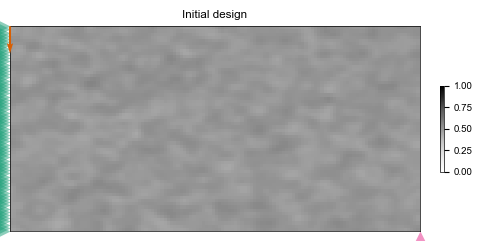

In [ ]:
initial_rho = design_parameterization(params, static, coords)
fig, ax = plot_design(initial_rho, problem, title="Initial design", legend=False)


(<Figure size 472.441x295.276 with 2 Axes>,
 <Axes: title={'center': 'Initial design'}>)

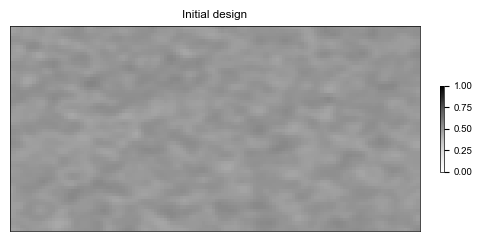

In [15]:
plot_design(initial_rho, title="Initial design", legend=False)

Not very interesting, eh? Let's change that by performing optimization!

## Set up the optimization process
First, let's create a loss function which returns the compliance of a structure corresponding to the input set of parameters $\theta$ Note, that we also output the corresponding designs $\rho$. Later, this will be used to track how the structure changes across iterations.


In [20]:
def loss_fn(params):
    rho = design_parameterization(params, static, coords)
    non_discreteness = jnp.sum(4 * rho * (1 - rho)) / (Nx * Ny)
    compliance = solver(rho, problem) / problem["reference_compliance"]

    # add penalty for discreteness
    loss = compliance
    return loss, {"rho": rho, "non_discreteness": non_discreteness}

Now, let's define and initialize the Adam optimizer from Optax.

In [21]:
opt = optax.adam(1e-4)
# Initialize with learnable parameters (only!)
opt_state = opt.init(params)

Finally, let's create functions for updating the neural network parameters based on gradients of the loss function. 

In [22]:
def make_step(params, opt_state):
    (loss, metrics), grads = eqx.filter_value_and_grad(loss_fn, has_aux=True)(params)

    updates, opt_state = opt.update(grads, opt_state, params)
    params = eqx.apply_updates(params, updates)

    return params, opt_state, loss, metrics

## Optimize the design
Rather than using a standard Python loop for optimization, we use JAX's scan function, which offers several advantages:

1. **Efficiency**: scan compiles the iteration into efficient XLA (Accelerated Linear Algebra) operations, making it significantly faster than Python loops.

2. **Automatic trajectory collection**: scan automatically accumulates auxiliary outputs (like losses and designs) during iteration, eliminating the need for manual list management.

3. **JIT compatibility**: Unlike Python loops, scan can be JIT-compiled, enabling further performance optimizations


We optimize for 100 steps. The code block below might take some time to run.

In [23]:
def scan_fn(carry, _):
    params, opt_state = carry
    params, opt_state, loss, metrics = make_step(params, opt_state)
    return (params, opt_state), (loss, metrics)


n_steps = 100

(params, opt_state), (losses, metrics) = scan(
    scan_fn,
    (params, opt_state),
    None,
    length=n_steps + 1,  # For the final loss
    kind="lax",
)

Let's see what the optimized structure looks like.

<Axes: title={'center': 'Final design'}>

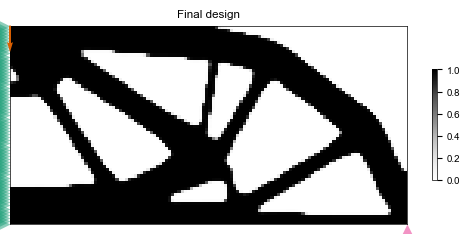

In [24]:
rhos = metrics["rho"]  # Extract the design from the metrics
non_discreteness = metrics["non_discreteness"]
plot_design(rhos[-1], problem, "Final design")

# Upscaling
One of the main benefits of neural reparameterization is that it can be easily evaluated at higher resolutions: 

<Axes: title={'center': 'Upscaled design'}>

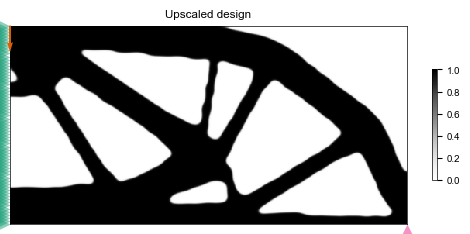

In [25]:
# Upscaling
uf = 4
domain_shape_upscaled = (Ny * uf, Nx * uf)
coords_upscaled = mtp.utils.get_grid_coords(domain_shape_upscaled)
rhos_upscaled = design_parameterization(
    params, static, coords_upscaled, domain_shape=domain_shape_upscaled
)
plot_design(rhos_upscaled, problem, "Upscaled design")

We can also plot the optimization trajectory to see how the design evolved throughout the iterations. The animation is saved to a separate file in the notebook directory.

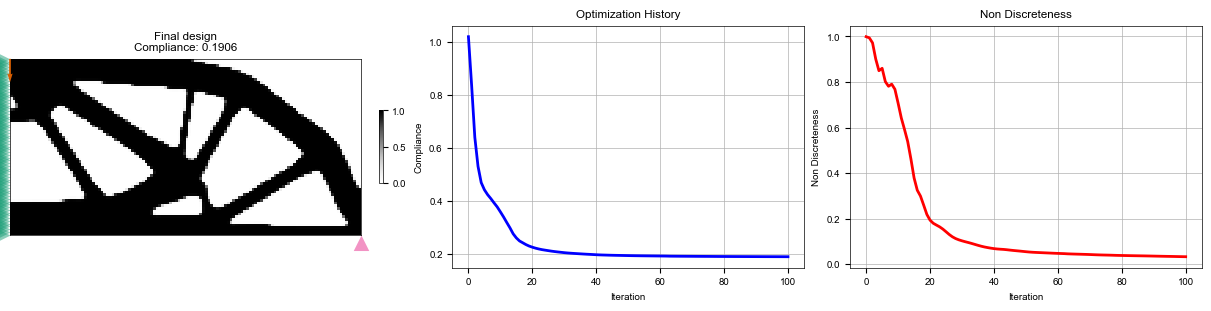

In [27]:
def plot_optimization_trajectory(rhos, losses, domain_shape):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")

    plot_design(
        rhos[-1], problem, f"Final design\nCompliance: {losses[-1]:.4f}", ax=ax1
    )

    # Plot loss history
    ax2.plot(losses, "b-", linewidth=2.0)
    ax2.set_title("Optimization History")
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Compliance")
    ax2.grid(True)

    ax3.plot(non_discreteness, "r-", linewidth=2.0)
    ax3.set_title("Non Discreteness")
    ax3.set_xlabel("Iteration")
    ax3.set_ylabel("Non Discreteness")
    ax3.grid(True)


plot_optimization_trajectory(rhos, losses, domain_shape)

## Next steps
This notebook introduced the fundamentals of neural topology optimization. When meta-learning, the demonstrated optimization procedure is vmapped across a batch of tasks to form the inner optimization loop. For further experimentation with different neural architectures, optimizers and problem settings, we recommend using the `experiment/neural_topology_optimization` script which uses Hydra configurations to make parameter exploration and experimentation straightforward and systematic.
